<a href="https://colab.research.google.com/github/7danielluna7/studious-computing-machine/blob/main/MAT301.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analizing MTA Bus Routes in the Bronx
**Author:** Daniel Luna Miranda

**Intro:**
 MTA buses are synonymous with traffic, especially as a Bronx native. I am going to use the concepts we learned in my analysis classes, like hypothesis testing, confidence intervals, and the central limit theorem, to really put to the test how slow buses go, because I know it really isn't our imagination.


**Video LINK:** [video](https://drive.google.com/file/d/1Uq3UHyZ8thcvaPvzYYdeIM1iMD-Kx-sO/view?usp=share_link)

## Table of Contents
1. [Data introduction](#section1)
2. [Data Cleaning and Wrangling](#section2)
3. [Visualizations](#section3)
4. [Probabality based on Observed Data](#section4)
5. [Probabality based on Normal Distribution (CLT)](#section5)
6. [Confidence Intervals](#section6)
7. [Hypothesis Testing](#section7)
8. [Chi-Square Tests](#section8)
9. [Extra Vizalization](#section9)


In [1]:
# importing all
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import norm, t, chisquare
import math


<a id="section1"></a>
## 1. Data Introduction

Data link: https://data.ny.gov/Transportation/MTA-Bus-Route-Segment-Speeds-2023-2024/58t6-89vi/about_data


This dataset provides data on how fast buses are traveling between pairs of subsequent timepoints (the major stops on a bus route) for every bus route in the system.

###Column Descriptions:
Year: The year for the data

Timestamp: Timestamp of the year, month, hour of week the data represents in a MM/DD/YYYY HH:MM:SS AM/PM format

Hour of Day: The hour the data is being aggregated to (0 to 23)

Route ID: The individual bus route

Direction: The direction of service (N, S, E, W)

Timepoint Stop ID / Name: The ID and name of the first of a pair of timepoint bus stops where speeds are measured

Timepoint Stop Latitude / Longitude: The geographic coordinates of the first timepoint bus stop

Next Timepoint Stop ID / Name: The ID and name of the second of a pair of timepoint bus stops where speeds are measured

Next Timepoint Stop Latitude / Longitude: The geographic coordinates of the second timepoint bus stop

Average Travel Time: The average travel time in minutes for all bus trips between the timepoint stops

Average Road Speed: The average speed in miles per hour for all bus trips between the timepoint stops

Bus Trip Count: The number of bus trips on the specific bus route between the subsequent timepoint bus stops

<a id="section2"></a>
## 1. Data Cleaning and Wrangling
Load data from personalized github link so you can follow along and make modifications

In [2]:
# loading data
url = 'https://raw.githubusercontent.com/7danielluna7/studious-computing-machine/main/MTA_Bus_Route_Segment_Speeds__2023_-_2024_20260517-2.csv'
df = pd.read_csv(url)
df.sample(10)

,Month,Timestamp,Day of Week,Hour of Day,Route ID,Direction,Route Type,Stop Order,Timepoint Stop ID,Timepoint Stop Name,Timepoint Stop Latitude,Timepoint Stop Longitude,Next Timepoint Stop ID,Next Timepoint Stop Name,Next Timepoint Stop Latitude,Next Timepoint Stop Longitude,Road Distance,Average Travel Time,Average Road Speed,Bus Trip Count
3913,7,2023 Jul 01 10:00:00 AM,Sunday,10,BXM1,N,Express,13,404250,BROADWAY/W 207 ST,40.867705,-73.920997,984006,W 230 ST / BROADWAY,40.877199,-73.906891,1.027,5.809992,10.605867,5
57314,7,2023 Jul 01 12:00:00 AM,Wednesday,0,BX11,W,Local,1,104068,HUGH GRANT CIR/CROSS BX SVC RD,40.832789,-73.860387,101455,BOSTON RD/SOUTHERN BL,40.837129,-73.888349,1.890,12.152088,9.331732,8
19040,7,2023 Jul 01 01:00:00 PM,Wednesday,13,BXM8,N,Express,7,450436,3 AV/E 87 ST,40.779424,-73.953443,450409,3 AV/E 120 ST,40.800675,-73.937943,1.676,7.216668,13.934414,8
41644,7,2023 Jul 01 12:00:00 PM,Saturday,12,BX12,W,Local,22,103999,E FORDHAM RD/WEBSTERAV,40.861596,-73.891066,104235,E FORDHAM RD/VALENTINE AV,40.862237,-73.895647,0.247,2.756862,5.375676,51
14009,7,2023 Jul 01 09:00:00 AM,Friday,9,BX3,N,Local,6,100149,UNIVERSITY AV/W 174 ST,40.846943,-73.920190,100155,UNIVERSITY AV/W BURNSIDE AV,40.854707,-73.911236,0.732,6.332940,6.935171,42
19074,7,2023 Jul 01 05:00:00 PM,Wednesday,17,BXM7,N,Express,7,450436,3 AV/E 87 ST,40.779424,-73.953443,450409,3 AV/E 120 ST,40.800675,-73.937943,1.676,7.705284,13.050785,41
53722,7,2023 Jul 01 07:00:00 AM,Monday,7,BX21,S,Local,28,101059,3 AV/E 163 ST,40.823866,-73.908942,101066,3 AV/E 150 ST,40.816142,-73.917547,0.728,7.278204,6.001479,39
46821,7,2023 Jul 01 07:00:00 AM,Monday,7,BX46,E,Local,1,104488,PROSPECT AV/WESTCHESTER AV,40.819315,-73.901848,104495,VIELE AV/CASANOVA ST,40.806177,-73.887932,1.486,11.244444,7.929247,9
83999,7,2023 Jul 01 10:00:00 PM,Sunday,22,BX7,S,Local,9,103208,HENRY HUDSON PKY W/W 246 ST,40.893316,-73.908526,102995,W 231 ST/CORLEAR AV,40.880164,-73.907304,1.037,5.595000,11.120643,20
67919,7,2023 Jul 01 11:00:00 PM,Saturday,23,BX5,W,Local,1,802168,PARKING RAMP/ACCESS RD,40.865450,-73.827810,103255,EDSON AV/BARTOW AV,40.868050,-73.833120,0.769,4.662126,9.896774,11


In [3]:
df.info()
#I am working with balaced dataset and it seems to be complete with no missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88383 entries, 0 to 88382
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Month                          88383 non-null  int64  
 1   Timestamp                      88383 non-null  object 
 2   Day of Week                    88383 non-null  object 
 3   Hour of Day                    88383 non-null  int64  
 4   Route ID                       88383 non-null  object 
 5   Direction                      88383 non-null  object 
 6   Route Type                     88383 non-null  object 
 7   Stop Order                     88383 non-null  int64  
 8   Timepoint Stop ID              88383 non-null  int64  
 9   Timepoint Stop Name            88383 non-null  object 
 10  Timepoint Stop Latitude        88383 non-null  float64
 11  Timepoint Stop Longitude       88383 non-null  float64
 12  Next Timepoint Stop ID         88383 non-null 

In [4]:
df.describe(include='all')
#

,Month,Timestamp,Day of Week,Hour of Day,Route ID,Direction,Route Type,Stop Order,Timepoint Stop ID,Timepoint Stop Name,Timepoint Stop Latitude,Timepoint Stop Longitude,Next Timepoint Stop ID,Next Timepoint Stop Name,Next Timepoint Stop Latitude,Next Timepoint Stop Longitude,Road Distance,Average Travel Time,Average Road Speed,Bus Trip Count
count,88383.0,88383,88383,88383.000000,88383,88383,88383,88383.000000,88383.000000,88383,88383.000000,88383.000000,88383.000000,88383,88383.000000,88383.000000,88383.000000,88383.000000,88383.000000,88383.000000
unique,NaN,24,7,NaN,57,4,4,NaN,NaN,358,NaN,NaN,NaN,355,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,2023 Jul 01 05:00:00 PM,Tuesday,NaN,BX22,S,Local,NaN,NaN,BAINBRIDGE AV/E 206 ST,NaN,NaN,NaN,BAINBRIDGE AV/E 206 ST,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4394,13204,NaN,3027,26479,69491,NaN,NaN,939,NaN,NaN,NaN,1190,NaN,NaN,NaN,NaN,NaN,NaN
mean,7.0,NaN,NaN,12.814399,NaN,NaN,NaN,13.501929,208480.811593,NaN,40.845087,-73.886939,242168.608839,NaN,40.845024,-73.887014,1.318157,9.032825,8.563868,15.399375
std,0.0,NaN,NaN,6.349451,NaN,NaN,NaN,9.811776,232106.578024,NaN,0.032470,0.040141,268410.815267,NaN,0.032506,0.040245,1.270624,5.729636,3.523796,9.852824
min,7.0,NaN,NaN,0.000000,NaN,NaN,NaN,1.000000,100014.000000,NaN,40.704931,-74.014819,100014.000000,NaN,40.705797,-74.013476,0.025000,0.266640,0.246640,1.000000
25%,7.0,NaN,NaN,8.000000,NaN,NaN,NaN,6.000000,101289.000000,NaN,40.826582,-73.911123,101335.000000,NaN,40.826582,-73.911123,0.677000,5.466174,6.273759,8.000000
50%,7.0,NaN,NaN,13.000000,NaN,NaN,NaN,12.000000,103152.000000,NaN,40.846943,-73.890431,103105.000000,NaN,40.846910,-73.890313,1.042000,7.731810,7.746522,14.000000
75%,7.0,NaN,NaN,18.000000,NaN,NaN,NaN,20.000000,104517.000000,NaN,40.868050,-73.857362,150139.000000,NaN,40.867880,-73.857362,1.497000,10.913124,9.908632,21.000000


From the describe method, I can conclude that this is a large dataset with precise location data, making it ideal for testing speed relative to location.

In [5]:
#making a copy of data just incase I want to compare
df_copy = df.copy()

# subsetting my columns of interest
keep_cols = ['Route ID', 'Direction', 'Route Type', 'Average Travel Time', 'Average Road Speed', 'Bus Trip Count','Day of Week','Hour of Day']
df = df[keep_cols]

In [6]:
# Checking for duplicate rows
print("\nCheck for duplicates")
print(df.duplicated().sum())


Check for duplicates
0


In [7]:
df['Route Type'].unique()

array(['Local', 'Express', 'Limited', 'SBS'], dtype=object)

In [8]:
df['Route ID'].unique()

array(['BX42', 'BXM1', 'BX35', 'BX27', 'BX36', 'BX4', 'BXM2', 'BX39',
       'BX33', 'BX24', 'BXM11', 'BX12', 'BX12+', 'BX3', 'BXM7', 'BXM18',
       'BX40', 'BX41', 'BX9', 'BX10', 'BXM4', 'BXM3', 'BX22', 'BXM9',
       'BX32', 'BX26', 'BX25', 'BX15', 'BX8', 'BX16', 'BX31', 'BXM10',
       'BX13', 'BX5', 'BXM8', 'BXM6', 'BX21', 'BX17', 'BX11', 'BX34',
       'BX7', 'BX23', 'BX20', 'BX28', 'BX38', 'BX19', 'BX46', 'BX6',
       'BX6+', 'BX4A', 'BX29', 'BX41+', 'BX2', 'BX1', 'BX18A', 'BX30',
       'BX18B'], dtype=object)

From the Route Id, I can see that there are buses heading to Manhattan, including select and local buses. To maintain data integrity, I will ensure I am working only with Bronx data and will create a custom column indicating whether the bus is bound for Manhattan.

In [9]:
#Creating an apply funtion if route Id contains M, the mus travels no nanhatan.
def goes_to_manhattan(x):
    if 'M' in x:
        return "yes"
    else:
        return "no"
df['goes_to_manhattan'] = df['Route ID'].apply(goes_to_manhattan)
df.head()

,Route ID,Direction,Route Type,Average Travel Time,Average Road Speed,Bus Trip Count,Day of Week,Hour of Day,goes_to_manhattan
0,BX42,E,Local,13.196874,9.188541,16,Wednesday,18,no
1,BXM1,S,Express,5.500008,8.912719,4,Wednesday,21,yes
2,BX42,E,Local,11.138460,10.886604,13,Wednesday,8,no
3,BXM1,N,Express,7.160418,8.605646,8,Wednesday,16,yes
4,BXM1,S,Express,5.802780,8.447675,12,Wednesday,7,yes


In [10]:

# fixing the categorical columns to be standardized using map and apply
df['Direction'] = df['Direction'].map({'N': 'north', 'S': 'south', 'E': 'east', 'W': 'west'})
# standardizing express and local route types
def standardized(x):
    x = x.lower()
    x = x.strip()
    return x
df['Day of Week'] = df['Day of Week'].apply(standardized)
df['Route Type'] = df['Route Type'].apply(standardized)
df.head()

,Route ID,Direction,Route Type,Average Travel Time,Average Road Speed,Bus Trip Count,Day of Week,Hour of Day,goes_to_manhattan
0,BX42,east,local,13.196874,9.188541,16,wednesday,18,no
1,BXM1,south,express,5.500008,8.912719,4,wednesday,21,yes
2,BX42,east,local,11.138460,10.886604,13,wednesday,8,no
3,BXM1,north,express,7.160418,8.605646,8,wednesday,16,yes
4,BXM1,south,express,5.802780,8.447675,12,wednesday,7,yes


####Having a good mixture of both categorical and numerical data is valuable, but I should create visualizations to truly understand what the data might reveal.

<a id="section3"></a>
## 3. Visualizations
First, I will use a pairplot to identify any connections that might help me formulate hypotheses about bus speed.


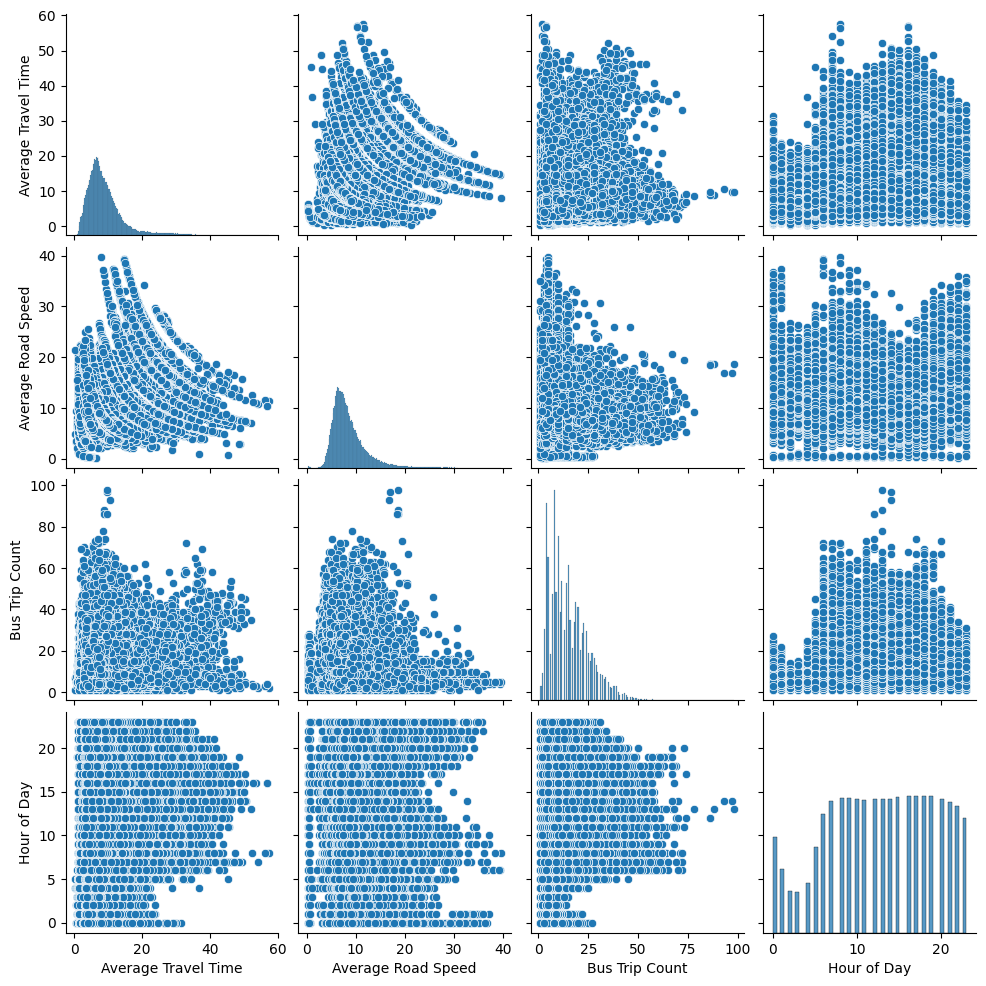

In [11]:
#PairPlot
sns.pairplot(df)


**Observation:** I believe that the time of day likely affects the average speed. From a biased viewpoint, I would expect to see more outliers in the speed data, but this also reminds me that there are speed limits and thats why avg speed stays at close a specific range. I then decided to use a histogram to view the speed of the dataset

A histogram will clarify the overall speed of all the buses. It will also support my previous claim that buses in nyc stay at a certain range.

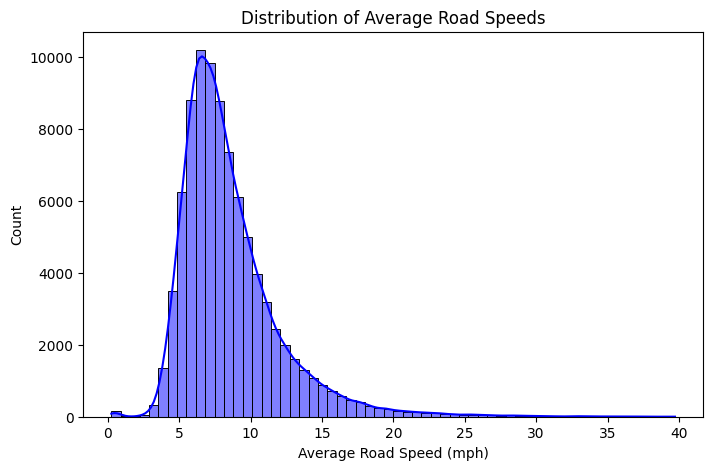

In [12]:
# Histogram
plt.figure(figsize=(8, 5))
sns.histplot(df['Average Road Speed'], bins=60, kde=True, color='blue')
plt.title('Distribution of Average Road Speeds')
plt.xlabel('Average Road Speed (mph)')
plt.show()

**Observation:** The histogram shows that the average bus speed in the Bronx is right-skewed, with most buses traveling between 6 and 11 miles per hour. This histogram also helped me categorize slow vs fast.

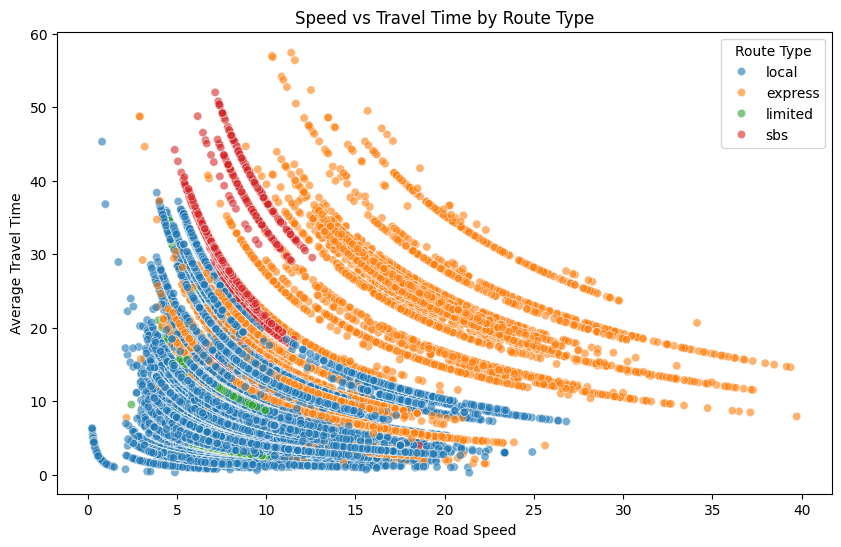

In [13]:
# Scatterplot with 3 dimensions

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Average Road Speed', y='Average Travel Time', hue='Route Type', data=df, alpha=0.6)
plt.title('Speed vs Travel Time by Route Type')
plt.show()

**Observation:** The scatterplot reveals 2 interesting obsertations that we can see if you are regular bus rider.
one is that express busses take the highway and meaning the passenders stay longer and that explains outliers.

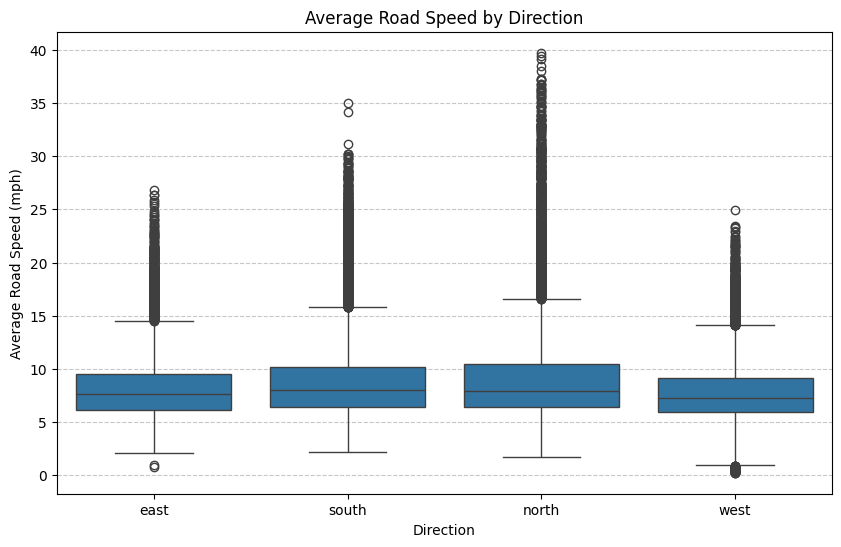

In [14]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Direction', y='Average Road Speed', data=df, )
plt.title('Average Road Speed by Direction')
plt.xlabel('Direction')
plt.ylabel('Average Road Speed (mph)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Observations** This box plot highlights the most interesting frames and observations of my data. Since I initially asked whether buses are slow, the box plot reveals notable separation worth further investigation. For example, the northbound direction appears faster on average. I am also curious whether the time of day influences bus speed, possibly because fewer people travel north during certain times, resulting in less traffic.



```
# This is formatted as code
```

<a id="section4"></a>
## 4. Probability based on Observed data


In this section, I analyze how bus direction or type affects trip speed or average trip length. I also want to see if direction or bus route influence average speed. I calculate probabilities based on my sample to estimate, because they do not represent the entire pupulation.


In [15]:
#calculate total len of data set
total_n = len(df)

local = df[df['Route Type'] == 'local']
express = df[df['Route Type'] == 'express']
limited = df[df['Route Type'] == 'limited']


In [16]:
#Probability a bus is 'express' AND 'goes_to_manhattan'

express_manhattan_count = len(df[(df['Route Type'] == 'express') & (df['goes_to_manhattan'] == 'yes')])
prob_and = (express_manhattan_count / total_n) * 100
print("Express and goes to Manhattan:")
print(f"f {prob_and:.2f}%")


Express and goes to Manhattan:
f 17.41%


simple starter probability question and a small preview of what statitics can really do

In [17]:


#Probability a bus is 'south' OR 'limited'
south_or_limited_count = len(df[(df['Direction'] == 'south') | (df['Route Type'] == 'limited')])
prob_or = (south_or_limited_count / total_n) * 100
print(f"Southbound OR Limited: {prob_or:.2f}%")

Southbound OR Limited: 31.25%


an or question is like an union and will get higher change of something happening.

In [18]:
#given a mean treshold of all buses avg speed, what percentage of bus directions are above that treshold
meanthreshold = df['Average Road Speed'].mean()

total_counts_dir = df.groupby('Direction')['Average Road Speed'].count()
fast_counts_dir = df[df['Average Road Speed'] > meanthreshold].groupby('Direction')['Average Road Speed'].count()
fast_proportions_dir = (fast_counts_dir / total_counts_dir * 100).round(1)
print(f"Percentage chance of a bus being fast {meanthreshold} given its direction:")
print(fast_proportions_dir.sort_values(ascending=False))

Percentage chance of a bus being fast 8.563867881223588 given its direction:
Direction
north    42.2
south    41.7
east     36.1
west     31.6
Name: Average Road Speed, dtype: float64


In this conditional probabily, i will using a speed tresdhold to further analize if direction has an effect on average speed. From this test I observed that north and south bound buses are considered faster.

In [19]:
# given a median treshold of all buses what percentage of a type of bus go over that median speed
medianthreshold = df['Average Road Speed'].median()

total_counts_type = df.groupby('Route Type')['Average Road Speed'].count()
fast_counts_type = df[df['Average Road Speed'] > medianthreshold].groupby('Route Type')['Average Road Speed'].count()
fast_proportions_dir = (fast_counts_type / total_counts_type * 100).round(1)
print(f"Percentage chance of a bus being fast {medianthreshold} given its type:")
print(fast_proportions_dir.sort_values(ascending=False))

Percentage chance of a bus being fast 7.74652226698 given its type:
Route Type
express    83.6
sbs        71.2
local      42.9
limited    21.2
Name: Average Road Speed, dtype: float64


In this analysis, I wanted to use math to show that the previous test wasn't a fluke. The goal is to demonstrate that a significant percentage of a bus's speed comes from specific factors, giving real meaning to the word 'express.'

<a id="section5"></a>
## 5. Probailities based on normal distibution

In this section, I will check if my data is normally distributed. First, let's check the histograms for all the numerical columns. I will then decide what type of test I should run depending on the results


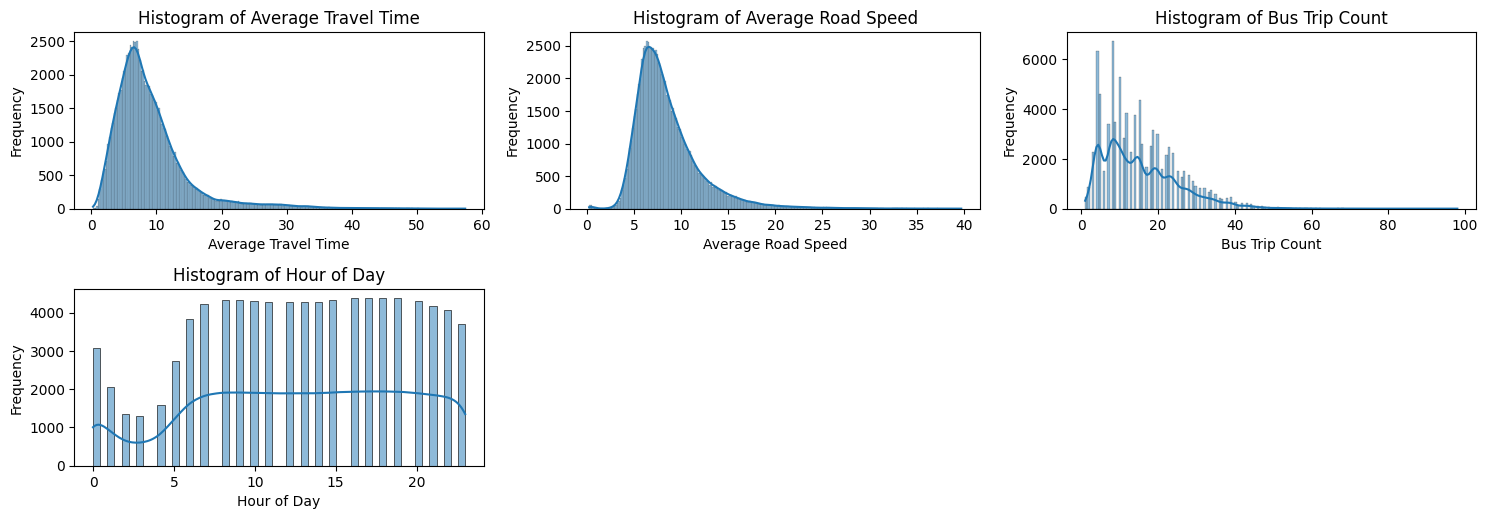

In [20]:
numerical_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 3, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


**Observation:** All of my data is approximately not normally distributed and skews heavily to the right, therefore will skip qq-plot. This also means I need to apply the Central Limit Theorem with a sample of at least 30 to make population predictions. This approach allows us to estimate probabilities without having the complete dataset.


In [21]:
import scipy.stats as stats
#question 1: get the mean and std for speed
mean = df['Average Road Speed'].mean()
std = df['Average Road Speed'].std()
n = 50
#standard eror
se = std / np.sqrt(n)
probability = 1 - stats.norm.cdf(10,mean,se)

print("the probalilty a sample of 50 will ride in a bus atleast 10 mph", probability*100)

the probalilty a sample of 50 will ride in a bus atleast 10 mph 0.19768557677322107


a one in five chance that you are riding in a bus slower than 10 miles gives a pictures of a slow bus ride

In [22]:
# question 2: Probability that a sample mean is less than a value
mean_time = df['Average Travel Time'].mean()
std_time = df['Average Travel Time'].std()
n_time = 40

# Calculate standard error
se_time = std_time / np.sqrt(n_time)

# Calculate probability that sample mean is less than 15 minutes
prob_less_15 = stats.norm.cdf(15, mean_time, se_time)

print("The probability a sample of 40 trips averages less than 15 mins:", prob_less_15 * 100)

The probability a sample of 40 trips averages less than 15 mins: 99.99999999775233


From an outside perspective, this indicates that people travel at least 15 minutes by bus to reach their destination, providing a clear view of how NYC transportation is reliable.

In [23]:
# Probability that a sample mean is between two values
mean_trips = df['Bus Trip Count'].mean()
std_trips = df['Bus Trip Count'].std()
n_trips = 60

# Calculate standard error
se_trips = std_trips / np.sqrt(n_trips)

# Calculate probability for the upper and lower bounds
prob_upper = stats.norm.cdf(20, mean_trips, se_trips)
prob_lower = stats.norm.cdf(15, mean_trips, se_trips)

# Subtract lower from upper to get the area strictly between them
prob_between = prob_upper - prob_lower

print("The probability a sample of 60 averages between 15 and 20 trips:", prob_between * 100)

The probability a sample of 60 averages between 15 and 20 trips: 62.3081210181678


I wanted to show what was the probilty of buses in nyc count being relative high. 15-20 trips is a high number, but sometimes we unapreciate this number.

<a id="section6"></a>
## 6. Confidence Intervals
In this section I will go over confidence intervals for an unknwon mean since my data is from 2023 - 2024 , only from the bronx and only for a week. using a t distributions allows me to make make a confidence interval even if my dataset is not complete and not possible to obtain pupulation standard deviation.

In [24]:
#calculate count of buses going express
express_count = len(df[df['Route Type'] == 'express'])
total_count = len(df)
print(total_count)
p_hat = express_count / total_count
se = np.sqrt((p_hat * (1 - p_hat)) / total_count)
alpha = 0.05

z_critical = stats.norm.ppf(1 - alpha/2)

# Margin of error
margin_of_error_prop = z_critical * se

# Confidence interval
ci_lower_prop = p_hat - margin_of_error_prop
ci_upper_prop = p_hat + margin_of_error_prop

print(f"95% Confidence Interval for the Proportion of express buses : ({ci_lower_prop:.2f}, {ci_upper_prop:.2f})")

88383
95% Confidence Interval for the Proportion of express buses : (0.17, 0.18)


Based on our dataset, we are 95% confident that the true proportion of all Bronx MTA bus trips that are 'express' routes falls between 17 % and 18%. since my dataset is large my standrad error becomes small.

In [25]:
import numpy as np
import scipy.stats as stats

# First, isolate the data to only buses going to Manhattan since in my hypothesis i want to compare specific bus routes
manhattan_buses = df[df['goes_to_manhattan'] == 'yes']

# Calculate how many buses travel under 10 mph
slow_count = len(manhattan_buses[manhattan_buses['Average Road Speed'] < 10])
total_count = len(manhattan_buses)

# Proportion and standard error
p_hat = slow_count / total_count
se = np.sqrt((p_hat * (1 - p_hat)) / total_count)

alpha = 0.05
z_critical = stats.norm.ppf(1 - alpha/2)

# Margin of error
margin_of_error_prop = z_critical * se

# Confidence interval
ci_lower_prop = p_hat - margin_of_error_prop
ci_upper_prop = p_hat + margin_of_error_prop

print(f"95% Confidence Interval for the Proportion of Slow Manhattan-bound buses: ({ci_lower_prop:.2f}, {ci_upper_prop:.2f})")

95% Confidence Interval for the Proportion of Slow Manhattan-bound buses: (0.41, 0.43)


We are 95% confident that the true proportion slow buses in the population lies between 41% and 43%. This means that if we were to repeatedly sample from the data, approximately 95% of those intervals would contain slow buses that travel to Manhattan.

In [26]:
import numpy as np
import scipy.stats as stats

# calculate confidence interval for average speed of entire dataset
mean = df['Average Road Speed'].mean()
std = df['Average Road Speed'].std()

#frind pdf and degres of freedom
t_critical = stats.t.ppf(1 - alpha/2, n-1)
se = std / np.sqrt(n)

margin_of_error = t_critical * se
ci_lower = mean - margin_of_error
ci_upper = mean + margin_of_error

print(f"95% Confidence Interval for the mean average road speeds: ({ci_lower:.2f}, {ci_upper:.2f})")

95% Confidence Interval for the mean average road speeds: (7.56, 9.57)


We are 95% confident that the true average road speed for all Bronx MTA buses falls between 7.44 and 9.69 mph.

In [27]:
#calculate confidence interval for mean average travel time
mean = df['Average Travel Time'].mean()
std = df['Average Travel Time'].std()

#frind pdf and degres of freedom
t_critical = stats.t.ppf(1 - .01/2, n-1)
se = std / np.sqrt(n)

margin_of_error = t_critical * se
ci_lower = mean - margin_of_error
ci_upper = mean + margin_of_error

print(f"99% Confidence Interval for average travel times : ({ci_lower:.2f}, {ci_upper:.2f})")

99% Confidence Interval for average travel times : (6.86, 11.20)


We are 99% confident that the true average travel time for a Bronx MTA bus trip falls between 6.58, 11.49.


<a id="section7"></a>
## 7. Hypothesis Testing
In this section I want to test if a random bus in going south is slower than a bus going north by a mathematical significance. I will use a null hypothesis and test uusing one sanple and  two-sample test.


[Null Hypothesis ( 𝐻0 ):  uN=uS  (The average speed of a south bound bus is

the same as a northbound bus.)
Alternative Hypothesis ( 𝐻1 ):  uN≠uS  (The average speed of a south bound bus is different as a northbound bus)

In [28]:
from statsmodels.stats.proportion import proportions_ztest

# Filter the data avg speed from north and south
north_speed = df[df['Direction'] == 'north']['Average Road Speed']
south_speed = df[df['Direction'] == 'south']['Average Road Speed']
#run a two-sample test
t_stat, p_value = stats.ttest_ind(north_speed, south_speed)

print(f"t-statistic: {t_stat}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("\nAt a 5% significance level, we Reject the null hypothesis.")
    print("There is a statistically significant difference in average speed between Northbound and Southbound buses.")
else:
    print("\nAt a 5% significance level, we Fail to reject the null hypothesis.")
    print("There is no statistically significant difference in average speed between the two directions.")

t-statistic: 7.323740541129527
P-value: 2.4458529777789973e-13

At a 5% significance level, we Reject the null hypothesis.
There is a statistically significant difference in average speed between Northbound and Southbound buses.


Hypotheses: - Null Hypothesis  𝐻0:𝜇𝑁<𝜇𝑆  (the average speed for a bus going south is slower than a north bound bus) - Alternative Hypothesis 𝐻1:𝜇𝑁>𝜇𝑆  (The average speed of south bus is not slower than a northbound train )

In [29]:
#run a one tail test
t_stat, p_value = stats.ttest_ind(north_speed, south_speed, alternative='greater')

print(f"t-statistic: {t_stat}")
print(f"P-value: {p_value}")
if p_value < alpha:
    print("At a 5% significance level, we Reject the null hypothesis.")
    print("There is a statistically significant evidence that Northbound buses are faster than Southbound buses.")
else:
    print("At a 5% significance level, we Fail to reject the null hypothesis.")
    print("There is no statistically significant evidence that Northbound buses are faster.")



t-statistic: 7.323740541129527
P-value: 1.2229264888894987e-13
At a 5% significance level, we Reject the null hypothesis.
There is a statistically significant evidence that Northbound buses are faster than Southbound buses.


[Null Hypothesis ( 𝐻0 ): uN=uS (The average speed of a bx31 is
the same as bx 32.) Alternative Hypothesis ( 𝐻1 ): uN≠uS (The average speed of a bx31  is the same as bx32)

In [30]:
import scipy.stats as stats
bx32_speed = df[df['Route ID'] == 'BX32']['Average Road Speed']
bx31_speed = df[df['Route ID'] == 'BX31']['Average Road Speed']

# Print the means to check your data
print(f"BX32 Mean Speed: {bx32_speed.mean():.2f} mph")
print(f"BX31 Mean Speed: {bx31_speed.mean():.2f} mph")

# Run the Two-Sample T-Test for Means (Welch's t-test)
t_stat, p_value = stats.ttest_ind(bx32_speed, bx31_speed, alternative='two-sided', equal_var=False)

print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {p_value:.4f}")

BX32 Mean Speed: 6.31 mph
BX31 Mean Speed: 8.62 mph
T-statistic: -46.22
P-value: 0.0000


For this hypothesis test, I wanted to verify whether two bus routes with similar northbound trips have similar average speeds. With a p-value of less than 0.05, we reject the null hypothesis and conclude that their average speeds are significantly different. Simiar direction did not have a significant influence in this example.

[Null Hypothesis ( 𝐻0 ): uN=uS (The average speed of a bx40 is
the same as bx 32.) Alternative Hypothesis ( 𝐻1 ): uN≠uS (The average speed of a bx31  is the same as bx42)

In [31]:
import scipy.stats as stats

# Isolate the speed data for the two routes, dropping any empty rows for safety
bx40_speed = df[df['Route ID'] == 'BX40']['Average Road Speed'].dropna()
bx42_speed = df[df['Route ID'] == 'BX42']['Average Road Speed'].dropna()

# Print the sample means to see the 0.20 mph difference
print(f"BX40 Mean Speed: {bx40_speed.mean():.2f} mph")
print(f"BX42 Mean Speed: {bx42_speed.mean():.2f} mph")

# Run Welch's Two-Sample T-Test (equal_var=False is key here)
t_stat_routes, p_value_routes = stats.ttest_ind(bx40_speed, bx42_speed, alternative='two-sided', equal_var=False)

print(f"T-statistic: {t_stat_routes:.2f}")
print(f"P-value: {p_value_routes:.4f}")

# Define the standard 5% significance level
alpha = 0.05

# Evaluate the p-value against our alpha
if p_value_routes < alpha:
    print("\nConclusion: At a 5% significance level, we Reject the Null Hypothesis.")
    print("The 0.20 mph difference is statistically significant. The routes do not operate at the same speed.")
else:
    print("\nConclusion: At a 5% significance level, we Fail to Reject the Null Hypothesis.")
    print("There is not enough statistical evidence to prove a difference. The 0.20 mph gap is likely just traffic noise, and the routes effectively operate at similar speeds.")

BX40 Mean Speed: 7.39 mph
BX42 Mean Speed: 7.14 mph
T-statistic: 3.99
P-value: 0.0001

Conclusion: At a 5% significance level, we Reject the Null Hypothesis.
The 0.20 mph difference is statistically significant. The routes do not operate at the same speed.


While the avergage means only differ .25 mph there was a low enough p value to reject the null hypothsis. From this test i learned that statistics is hard and the inportance of using different techniques.

Null Hypothesis (H
0
 ): There is no significant difference in the average road speeds of Northbound and Southbound buses (μ
North
 =μ
South
 ).
Alternative Hypothesis (H
1
 ): There is a statistically significant difference in the average road speeds of Northbound and Southbound buses (μ
North



=μ
South
​).

In [32]:
from statsmodels.stats.proportion import proportions_ztest

# Filter the data avg speed from north and south
north_speed = df[df['Direction'] == 'north']['Average Road Speed']
south_speed = df[df['Direction'] == 'south']['Average Road Speed']
#run a two-sample test
z_stat, p_value = stats.ttest_ind(north_speed, south_speed)

print(f"t-statistic: {z_stat}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("\nAt a 5% significance level, we Reject the null hypothesis.")
    print("There is a statistically significant difference in average speed between Northbound and Southbound buses.")
else:
    print("\nAt a 5% significance level, we Fail to reject the null hypothesis.")
    print("There is no statistically significant difference in average speed between the two directions.")

t-statistic: 7.323740541129527
P-value: 2.4458529777789973e-13

At a 5% significance level, we Reject the null hypothesis.
There is a statistically significant difference in average speed between Northbound and Southbound buses.


After running these tests and rejecting my null hypothesis, I want to continue and use a different method to really put the speed of these buses into perspective

<a id="section8"></a>
## 8. Chi-square test
If i had to the choice to take an exam at lehman college, would i choose tuesday or thurday?
I will use a chi square to compare these by maping my route of the bx22 and categorazing speed as the median or higher than the median as fast.


H
0
​
 : The speed of the BX22 is independent of the day of the week (Tuesday vs. Thursday).
H
1
​
 : There is a relationship between the speed of the BX22 and the day of the week.

In [33]:
from scipy.stats import chi2_contingency
# Isolate the BX22 route
bx22 = df[df['Route ID'] == 'BX22']

#  Filter using the standardized lowercase strings from your earlier cleaning step
bx22_days = bx22[bx22['Day of Week'].isin(['tuesday', 'thursday'])].copy()

#  Calculate a single scalar median to act as the threshold
median_threshold = bx22_days['Average Road Speed'].median()

# Create the contingency table
contingency_table = pd.crosstab(
    bx22_days['Day of Week'],
    bx22_days['Average Road Speed'].apply(lambda x: 'fast' if x >= median_threshold else 'slow')
)
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

alpha = 0.05
if p_value < alpha:
    print("\nConclusion: Reject the Null Hypothesis.")
else:
    print("\nConclusion: Fail to Reject the Null Hypothesis.")


Conclusion: Fail to Reject the Null Hypothesis.


 to evaluate the distribution of MTA bus route types in the Bronx. Based on my observations as a Bronx resident, I predict the system is broken down into four categories with the following expected proportions: 65% Local, 15% Limited, 10% Express, and 10% SBS. I will use this test to determine if the actual observed data fits my expected distribution.

 The observed distribution of Bronx bus route types perfectly matches the expected proportions (65% Local, 15% Limited, 10% Express, 10% SBS).
Alternative Hypothesis: observed distribution of Bronx bus route types significantly differs from the expected proportions.


In [34]:
from scipy.stats import chisquare

#Get the total count of ALL buses in the dataset
total_count = len(df)

# Lock in the exact order of your categories so they align with your proportions
categories = ['local', 'limited', 'express', 'sbs']
expected_proportions = [0.65, 0.15, 0.10, 0.10]

observed_counts = df['Route Type'].value_counts().loc[categories]

# Calculate the expected counts mathematically
expected_counts = [total_count * p for p in expected_proportions]


print(f"Observed: {observed_counts.values}")
print(f"Expected: {expected_counts}")


# Run the Chi-Square Goodness-of-Fit test
chi2_stat, p_value = chisquare(f_obs=observed_counts.values, f_exp=expected_counts)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"P-value: {p_value:.4e}")

alpha = 0.05
if p_value < alpha:
    print("\nAt a 5% significance level, we Reject the Null Hypothesis.")
    print("The actual distribution of bus types significantly differs from our predicted 65/15/10/10 split.")
else:
    print("\nAt a 5% significance level, we Fail to Reject the Null Hypothesis.")
    print("The actual distribution perfectly matches our predicted 65/15/10/10 split.")

Observed: [69491  1911 15386  1595]
Expected: [57448.950000000004, 13257.449999999999, 8838.300000000001, 8838.300000000001]
Chi-square statistic: 23021.9727
P-value: 0.0000e+00

At a 5% significance level, we Reject the Null Hypothesis.
The actual distribution of bus types significantly differs from our predicted 65/15/10/10 split.


calculated from the portion of the dataset i chose , how is the dataset distrubuted based on the type of bus. it puts into propected that the local buses run the city.

<a id="section9"></a>
# 9. Bus speed mapped out
used Kepler.gl to map out the average speed of buses at major stops. I wanted to analyze the overall performance of buses in the Bronx, and the visualization clearly shows that the closer you get to Manhattan, the lower the speed.Using a 3D model helps vizulize the Bronx and gives significance to location and speed.  As you move further north, the average speed of the buses increases. This leads me to conclude that the location of the bus stop has the greatest impact on speed, and my initial hypothesis about direction was just a coincidence.

![Your Alt Text](https://github.com/7danielluna7/studious-computing-machine/blob/main/bus%20map.jpg?raw=true)

